# Árboles de Decisión — Clasificación (Cell2Cell)

**Objetivo:** predecir `Churn` (abandono del cliente) con un `DecisionTreeClassifier`, ajustar hiperparámetros con `GridSearchCV`, calcular el umbral óptimo vía ROC y evaluar el margen de negocio de la campaña de retención.

- `cell2celltrain.csv`: 51,047 clientes (con etiqueta `Churn`)
- `cell2cellholdout.csv`: 20,000 clientes (sin etiqueta)
- TARGET: `Churn` → `No=0`, `Yes=1`

## 1. Librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    recall_score, precision_score, f1_score,
    roc_curve, roc_auc_score
)

## 2. Carga y preparación de datos

In [12]:
cell2cell_train = pd.read_csv('cell2celltrain.csv', sep=',', encoding='iso-8859-1')
cell2cell_holdout = pd.read_csv('cell2cellholdout.csv', sep=',', encoding='iso-8859-1')

print('Train:', cell2cell_train.shape)
print('Holdout:', cell2cell_holdout.shape)

# Convertimos TARGET a 0/1
cell2cell_train['Churn'] = cell2cell_train['Churn'].map({'No': 0, 'Yes': 1})
cell2cell_holdout['Churn'] = cell2cell_holdout['Churn'].map({'No': 0, 'Yes': 1})

print('\nDistribución Churn:')
print(cell2cell_train['Churn'].value_counts(normalize=True) * 100)

Train: (51047, 58)
Holdout: (20000, 58)

Distribución Churn:
Churn
0    71.18146
1    28.81854
Name: proportion, dtype: float64


In [3]:
# X, y — separamos predictores y target. CustomerID no aporta al modelo.
X = cell2cell_train.drop(columns=['Churn', 'CustomerID'])
y = cell2cell_train['Churn']

# Tipos
variables_numericas = X.select_dtypes(include=np.number).columns
variables_cualitativas = X.select_dtypes(exclude=np.number).columns

# Imputación (mediana numéricas / moda categóricas)
imputer_num = SimpleImputer(strategy='median')
X[variables_numericas] = imputer_num.fit_transform(X[variables_numericas])

imputer_cat = SimpleImputer(strategy='most_frequent')
X[variables_cualitativas] = imputer_cat.fit_transform(X[variables_cualitativas])

# One-Hot Encoding
X_encoded = pd.get_dummies(X, drop_first=True).astype(float)
print('Shape final X:', X_encoded.shape)
print('Nulos restantes:', X_encoded.isnull().sum().sum())

Shape final X: (51047, 829)
Nulos restantes: 0


## 3. Train / Test split

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

print('X_train:', X_train.shape, ' X_test:', X_test.shape)
print('y_train distribución:', y_train.value_counts(normalize=True).to_dict())
print('y_test distribución: ', y_test.value_counts(normalize=True).to_dict())

X_train: (40837, 829)  X_test: (10210, 829)
y_train distribución: {0: 0.711805470529177, 1: 0.288194529470823}
y_test distribución:  {0: 0.7118511263467189, 1: 0.2881488736532811}


## 4. Búsqueda de hiperparámetros (GridSearchCV)

Probamos combinaciones de `max_depth`, `min_samples_leaf` y `criterion` usando `roc_auc` como métrica de selección (apta para clases desbalanceadas). Usamos validación cruzada de 3 folds para mantener el tiempo de ejecución razonable. El mejor modelo según CV se almacena en `best_tree`.

In [5]:
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [6, 8, 10],
    'min_samples_leaf': [50, 100, 200],
    'class_weight': [None, 'balanced']
}

grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    scoring='roc_auc',
    cv=3,
    n_jobs=-1,
    verbose=0
)

grid.fit(X_train, y_train)

print('Mejores hiperparámetros:')
print(grid.best_params_)
print(f'\nMejor AUC-ROC (CV): {grid.best_score_:.4f}')

best_tree = grid.best_estimator_

Mejores hiperparámetros:
{'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 200}

Mejor AUC-ROC (CV): 0.6365


## 5. Modelo final e importancia de variables

Top 15 variables más importantes:


,Variable,Importancia
26,CurrentEquipmentDays,0.312608
21,MonthsInService,0.183153
6,PercChangeMinutes,0.097683
1,MonthlyMinutes,0.076394
2,TotalRecurringCharge,0.047407
7,PercChangeRevenues,0.040119
27,AgeHH1,0.028624
781,HandsetRefurbished_Yes,0.025397
4,OverageMinutes,0.024062
0,MonthlyRevenue,0.020560


/tmp/ipykernel_32642/989503410.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


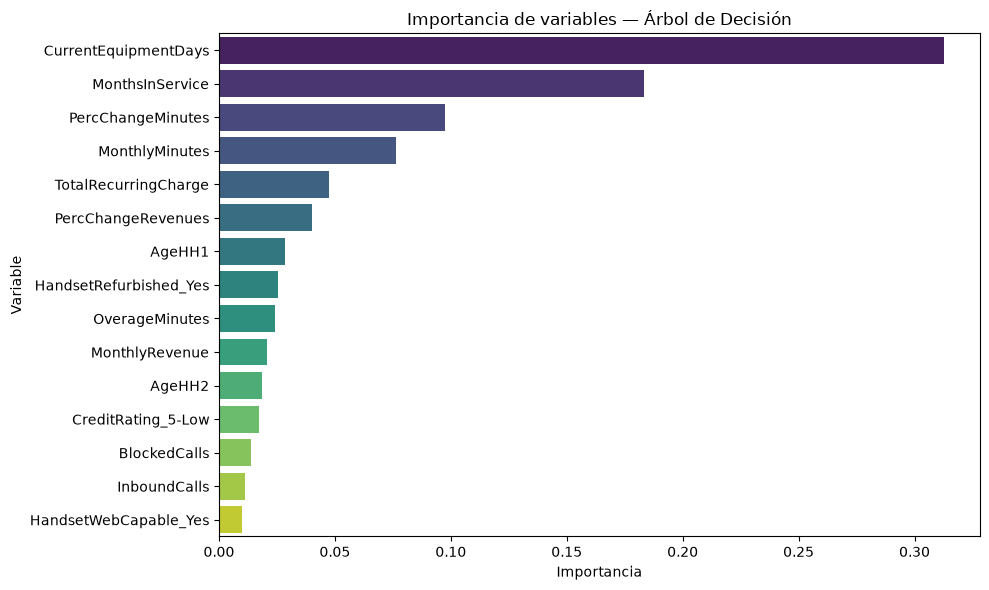

In [6]:
importancias = pd.DataFrame({
    'Variable': X_train.columns,
    'Importancia': best_tree.feature_importances_
}).sort_values('Importancia', ascending=False)

print('Top 15 variables más importantes:')
display(importancias.head(15))

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importancias.head(15),
    x='Importancia', y='Variable',
    palette='viridis'
)
plt.title('Importancia de variables — Árbol de Decisión')
plt.tight_layout()
plt.show()

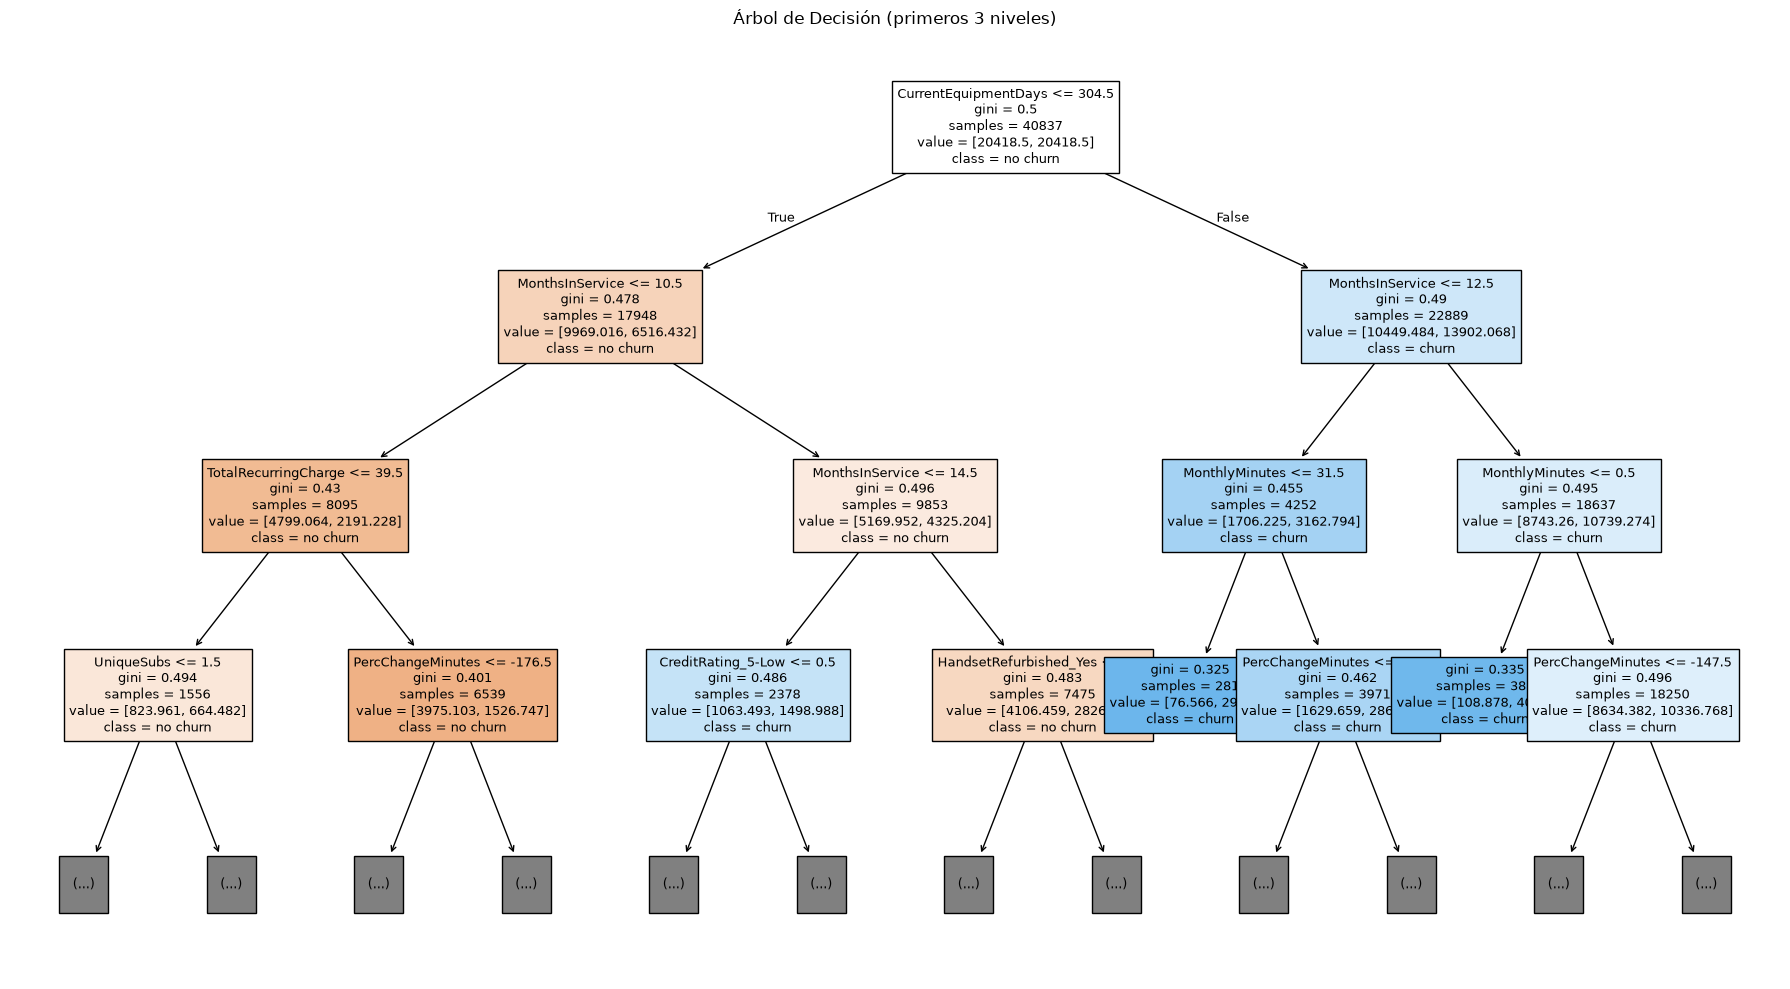

In [7]:
# Visualización del árbol (primeros 3 niveles)
plt.figure(figsize=(18, 10))
plot_tree(
    best_tree,
    max_depth=3,
    filled=True,
    feature_names=X_train.columns,
    class_names=['no churn', 'churn'],
    fontsize=9
)
plt.title('Árbol de Decisión (primeros 3 niveles)')
plt.tight_layout()
plt.show()

## 6. Probabilidades, umbral óptimo (ROC) y métricas

In [8]:
# Probabilidades de churn (clase 1) en test
y_proba = best_tree.predict_proba(X_test)[:, 1]

# Curva ROC y umbral óptimo (índice de Youden: tpr - fpr)
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
youden = tpr - fpr
optimal_threshold = thresholds[np.argmax(youden)]

print(f'ROC-AUC test: {roc_auc_score(y_test, y_proba):.4f}')
print(f'Umbral óptimo (Youden): {optimal_threshold:.4f}')

y_pred_opt = (y_proba >= optimal_threshold).astype(int)

ROC-AUC test: 0.6395
Umbral óptimo (Youden): 0.5233


In [9]:
# Matriz de confusión
cm = confusion_matrix(y_test, y_pred_opt)
print('Matriz de confusión (umbral óptimo):')
print(cm)
print(f'  VN={cm[0,0]}  FP={cm[0,1]}')
print(f'  FN={cm[1,0]}  VP={cm[1,1]}')

acc = accuracy_score(y_test, y_pred_opt)
rec = recall_score(y_test, y_pred_opt)
pre = precision_score(y_test, y_pred_opt)
f1  = f1_score(y_test, y_pred_opt)

print(f'\nAccuracy:  {acc:.4f}')
print(f'Recall:    {rec:.4f}')
print(f'Precision: {pre:.4f}')
print(f'F1-score:  {f1:.4f}')

print('\nReporte completo:')
print(classification_report(y_test, y_pred_opt, target_names=['No Churn', 'Churn']))

Matriz de confusión (umbral óptimo):
[[4435 2833]
 [1199 1743]]
  VN=4435  FP=2833
  FN=1199  VP=1743

Accuracy:  0.6051
Recall:    0.5925
Precision: 0.3809
F1-score:  0.4637

Reporte completo:
              precision    recall  f1-score   support

    No Churn       0.79      0.61      0.69      7268
       Churn       0.38      0.59      0.46      2942

    accuracy                           0.61     10210
   macro avg       0.58      0.60      0.58     10210
weighted avg       0.67      0.61      0.62     10210



## 7. Evaluación de negocio — Margen de la campaña de retención

Supuestos (ajustables):
- **Ingreso por cliente que acepta la oferta**: proxy calculado con la mediana real de `MonthlyRevenue` durante 12 meses.
- **Costo de contacto por cliente**: supuesto configurable, porque el dataset no incluye ese costo.
- Los **VP** son los contactados que efectivamente iban a abandonar (ganamos el ingreso).
- Los **FP** se contactan de más (pagamos el costo, pero no se iban a ir — pérdida).
- Los **VN** y **FN** no se contactan.

In [10]:
# Parámetros económicos
# El dataset no tiene precio de la oferta ni costo de contacto.
# Usamos MonthlyRevenue como proxy de ingreso mensual y suponemos 12 meses de retención.
meses_retencion = 12
ingreso_mensual_mediano = cell2cell_train['MonthlyRevenue'].median()
ingreso_por_acepta = ingreso_mensual_mediano * meses_retencion
costo_por_contacto = 30    # supuesto configurable (USD)

VP = cm[1,1]
FP = cm[0,1]
FN = cm[1,0]
VN = cm[0,0]

ingreso_total = VP * ingreso_por_acepta
costo_total   = (VP + FP) * costo_por_contacto
margen        = ingreso_total - costo_total

print(f'Contactados (VP+FP): {VP+FP}')
print(f'  VP (acertamos churn):    {VP}')
print(f'  FP (contactamos de más): {FP}')
print(f'Ingreso mensual mediano observado: ${ingreso_mensual_mediano:,.2f}')
print(f'Ingreso estimado por aceptación ({meses_retencion} meses): ${ingreso_por_acepta:,.2f}')
print(f'Ingreso total (VP × ingreso por aceptación): ${ingreso_total:,.0f}')
print(f'Costo total ((VP+FP) × ${costo_por_contacto}): ${costo_total:,.0f}')
print(f'MARGEN: ${margen:,.0f}')

if margen > 0:
    print('\n✓ El modelo deja margen POSITIVO — la campaña es rentable.')
else:
    print('\n✗ El modelo deja margen NEGATIVO — revisar parámetros económicos o el umbral.')

Contactados (VP+FP): 4576
  VP (acertamos churn):    1743
  FP (contactamos de más): 2833
Ingreso mensual mediano observado: $48.46
Ingreso estimado por aceptación (12 meses): $581.52
Ingreso total (VP × ingreso por aceptación): $1,013,589
Costo total ((VP+FP) × $30): $137,280
MARGEN: $876,309

✓ El modelo deja margen POSITIVO — la campaña es rentable.


In [11]:
# Escalamiento: ¿qué pasa si llevamos la campaña a toda la base?
n_total = cell2cell_train.shape[0]   # base completa de clientes
factor  = n_total / X_test.shape[0]  # extrapolación lineal al total

ingreso_total_e = ingreso_total * factor
costo_total_e   = costo_total   * factor
margen_e        = margen        * factor

print(f'Extrapolación a {n_total:,.0f} clientes (factor ×{factor:.1f}):')
print(f'  Ingreso estimado: ${ingreso_total_e:,.0f}')
print(f'  Costo estimado:   ${costo_total_e:,.0f}')
print(f'  MARGEN estimado:  ${margen_e:,.0f}')

Extrapolación a 51,047 clientes (factor ×5.0):
  Ingreso estimado: $5,067,649
  Costo estimado:   $686,360
  MARGEN estimado:  $4,381,289


## 8. Interpretación

- El árbol resultante muestra las variables que más separan a los clientes que abandonan.
- El umbral de Youden maximiza `tpr - fpr`, equilibrando detectar churners reales (recall) sin contactar demasiados clientes no churners (FP).
- El margen de negocio depende fuertemente de los parámetros `ingreso_por_acepta` y `costo_por_contacto`. Si el ingreso neto por churner recuperado supera el costo promedio de contacto, la campaña deja ganancia.
- Las variables con mayor importancia (`Top 15`) son las que la campaña debería usar para segmentar también sin modelo.